# SECOND — проверка Tiny Siamese без переобучения (v2)

Исправлено чтение подготовленного SECOND manifest: поддерживается `notebook_bounded21_protocol.json` → `identity.dataset_root`, а также другие сохранённые источники. Если есть hash, он проверяется.

**Run All** после Restart Kernel. Только validation, без обучения и без test.

Диагностика: per-class F1 и confusion matrix, качество ROI/меток, признаки недостаточного контекста и связь их с ошибками.


## 1. Настройки, подготовленный SECOND

`SEARCH_NAME` и лимиты выборки можно менять. Код использует проектный `src/satchange`, подготовленный manifest и финальный summary.

In [1]:
"""Validation-only audit for the user's Tiny Siamese SECOND classifier.

Use in Jupyter via `%run tiny_second_roi_diagnostics.py` or run as Python file.
This script does not train, modify checkpoints, invoke test, or change HPO protocols.
"""
from __future__ import annotations

import copy
import json
import math
import sys
from collections import Counter
from collections.abc import Mapping
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
import matplotlib.pyplot as plt

# ========================= EDIT ONLY THIS SECTION =========================
PROJECT_ROOT = Path('.')
SEARCH_NAME = 'second_oracle_bounded21_e15_25_40_65_bf16_w4_v1'
SEEDS = (42, 123, 777)         # Use (42,) for the quickest first check.
MAX_VAL_ROIS = 600             # None = all validation ROIs; no test data is opened.
MAX_TRAIN_AUDIT_ROIS = 600    # None = all train ROIs.
MAX_RAW_PURITY_ROIS = 100    # Expensive optional source-map alignment check.
AUDIT_SEED = 2026
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
# ========================================================================

ROOT = PROJECT_ROOT.expanduser().resolve()
sys.path.insert(0, str(ROOT / 'src'))
from satchange.models import TinySiameseChangeClassifier
from satchange.semantic.data import SemanticROIDataset
from satchange.semantic.second import discover_second
from satchange.utils import load_config

SEARCH = ROOT / 'artifacts/hyperparameter_search/semantic/tiny_siamese_second' / SEARCH_NAME
SUMMARY_FILE = SEARCH / 'final_training_summary.json'
PROTOCOL_FILE = SEARCH / 'pipeline_protocol.json'
OUTPUT = ROOT / 'artifacts' / 'debug' / 'tiny_second_roi_diagnostics' / SEARCH_NAME
OUTPUT.mkdir(parents=True, exist_ok=True)

if not SUMMARY_FILE.is_file() or not PROTOCOL_FILE.is_file():
    raise FileNotFoundError(f'Expected completed run in {SEARCH}; missing summary or protocol.')

summary = json.loads(SUMMARY_FILE.read_text(encoding='utf-8'))
protocol = json.loads(PROTOCOL_FILE.read_text(encoding='utf-8'))
if not summary.get('complete'):
    raise RuntimeError('Final training is incomplete. No test or training will be run.')
if protocol.get('context',{}).get('task') != 'semantic_roi_classification':
    raise RuntimeError('This is not a semantic classifier protocol.')
# The bounded21 runner may store its training manifest in the notebook's
# scientific identity rather than at pipeline_protocol['dataset_root'].
# This is a READ-ONLY lookup: never regenerate ROI or change the old protocol.
import hashlib


def resolve_manifest_from_training(search, protocol, summary, project_root):
    identity_file = search / 'notebook_bounded21_protocol.json'
    identity = {}
    if identity_file.is_file():
        budget_doc = json.loads(identity_file.read_text(encoding='utf-8'))
        identity = budget_doc.get('identity', {})
        if not isinstance(identity, dict):
            raise ValueError(f'Invalid bounded21 identity in {identity_file}')

    candidates = [
        ('notebook_bounded21_protocol.identity.dataset_root', identity.get('dataset_root')),
        ('pipeline_protocol.dataset_root', protocol.get('dataset_root')),
        ('pipeline_protocol.context.dataset_root', protocol.get('context', {}).get('dataset_root')),
        ('pipeline_protocol.base.dataset_root', protocol.get('base', {}).get('dataset_root')),
    ]
    for row in summary.get('results', []):
        if isinstance(row, dict):
            params = row.get('parameters', {})
            if isinstance(params, dict):
                seed = params.get('seed', '?')
                candidates.append((f'final_summary.seed_{seed}.parameters.dataset_root',
                                   params.get('dataset_root')))

    valid = {}
    seen = []
    for origin, value in candidates:
        if not isinstance(value, str) or not value.strip():
            continue
        path = Path(value).expanduser()
        if not path.is_absolute():
            path = project_root / path
        path = path.resolve()
        seen.append(f'{origin}: {path} ({"file" if path.is_file() else "not a file"})')
        if path.is_file() and path.suffix.lower() == '.json':
            valid.setdefault(path, []).append(origin)

    if not valid:
        raise FileNotFoundError(
            'Prepared SECOND manifest was not found in either training protocol or final summary.\n'
            'Candidates checked:\n' + ('\n'.join(seen) if seen else '(none)') + '\n'
            'Specify the actual prepared manifest path in the first cell after checking '
            'the saved notebook_bounded21_protocol.json (do not call prepare_second again).'
        )
    if len(valid) != 1:
        raise RuntimeError(
            'Conflicting existing SECOND manifests in saved experiment metadata; refusing '
            'to evaluate checkpoints on an ambiguous dataset:\n' +
            '\n'.join(f'{p} <- {owners}' for p, owners in valid.items())
        )
    path, locations = next(iter(valid.items()))
    expected_hash = identity.get('manifest_sha256')
    if expected_hash:
        sha = hashlib.sha256()
        with path.open('rb') as file:
            for block in iter(lambda: file.read(1024 * 1024), b''):
                sha.update(block)
        if sha.hexdigest() != expected_hash:
            raise RuntimeError(
                f'SECOND manifest SHA256 mismatch: {path}. '
                'Do not evaluate on modified data or overwrite the HPO protocol.'
            )
    print('Training manifest source:', ', '.join(locations))
    return path


manifest = resolve_manifest_from_training(SEARCH, protocol, summary, ROOT)

config = copy.deepcopy(load_config(ROOT / 'configs/tiny_siamese_change_classifier.yaml'))
base = protocol['base']
config.update(copy.deepcopy(base['semantic_config']))
config['dropout'] = base['model_parameters']['dropout']
config.setdefault('training',{}).update({key:copy.deepcopy(base[key])
    for key in ('batch_size','num_workers','precision','tf32','class_weights') if key in base})
classes = tuple(config['classes'])
K = len(classes)
val_ds = SemanticROIDataset(manifest, 'val', config)
train_ds = SemanticROIDataset(manifest, 'train', config)
if len(val_ds) == 0 or len(train_ds) == 0:
    raise RuntimeError('The prepared manifest has no train or val ROIs.')

rng = np.random.default_rng(AUDIT_SEED)
def indices_for(length, limit):
    return np.sort(rng.choice(length, size=min(length,limit), replace=False)) if limit is not None else np.arange(length)
val_ids = indices_for(len(val_ds), MAX_VAL_ROIS)
train_ids = indices_for(len(train_ds), MAX_TRAIN_AUDIT_ROIS)

print('Model:', 'TinySiameseChangeClassifier', '| classes:', classes)
print('Prepared manifest:', manifest)
print('Data count train / val:', len(train_ds), '/', len(val_ds))
print('Samples audited: train', len(train_ids), '/ val', len(val_ids))
print('Important: ONLY validation predictions; NO test set and NO training.')
print('Diagnostic output:', OUTPUT)



Training manifest source: notebook_bounded21_protocol.identity.dataset_root, pipeline_protocol.context.dataset_root
Model: TinySiameseChangeClassifier | classes: ('non-vegetated ground surface', 'tree', 'low vegetation', 'water', 'buildings', 'playgrounds')
Prepared manifest: data/SECOND_semantic_cache/0590eed622ef37dcdf469c09be6cd5d83186109d499e755590f1177569d7f7fc/rois/prepared.json
Data count train / val: 26867 / 5904
Samples audited: train 600 / val 600
Important: ONLY validation predictions; NO test set and NO training.
Diagnostic output: artifacts/debug/tiny_second_roi_diagnostics/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1


## 2. Загрузка best.pt

Только checkpoints собственного завершённого обучения. Загрузка выполняется один раз на seed.

In [2]:
# ------------------- checkpoint loading (trusted own .pt) -----------------
def normalize_key(key):
    for prefix in ('module.','_orig_mod.','model.','network.'):
        while key.startswith(prefix):
            key = key[len(prefix):]
    return key

def find_model_state(obj, expected, depth=0):
    if depth > 5:
        return None
    if isinstance(obj, torch.nn.Module):
        obj = obj.state_dict()
    if isinstance(obj, Mapping):
        tensors = {normalize_key(k):v for k,v in obj.items()
                   if isinstance(k,str) and torch.is_tensor(v)}
        if expected.issubset(tensors):
            return {key:tensors[key] for key in expected}
        # Only checkpoint payload keys can carry a model; never accidentally take optimizer state.
        for key in ('model_state_dict','model_state','state_dict','model','weights',
                    'best_weights','best_model_state_dict','best_state_dict',
                    'model_weights','network','checkpoint'):
            if key in obj:
                found = find_model_state(obj[key],expected,depth+1)
                if found is not None:
                    return found
        # Some project checkpoints use other wrapper names. Expected tensor keys
        # are still mandatory, so arbitrary optimizer dictionaries cannot match.
        for child in obj.values():
            if isinstance(child,(Mapping,torch.nn.Module)):
                found=find_model_state(child,expected,depth+1)
                if found is not None:
                    return found
    return None

def load_model(seed):
    ckpts = summary['best_checkpoints']
    path = ckpts.get(str(seed), ckpts.get(seed))
    if path is None:
        raise KeyError(f'seed {seed} not in final checkpoints: {list(ckpts)}')
    path = Path(path).resolve()
    if not path.is_file():
        raise FileNotFoundError(path)
    records = summary.get('results',[])
    params = next((row.get('parameters',{}) for row in records
                   if int(row.get('parameters',{}).get('seed',-1)) == seed), {})
    dropout = params.get('model_parameters',{}).get('dropout',config['dropout'])
    model = TinySiameseChangeClassifier(classes,dropout=dropout)
    # These checkpoints are generated by the user's own training system.
    # Do not load third-party/untrusted checkpoints with weights_only=False.
    state = torch.load(path,map_location='cpu',weights_only=False)
    weights = find_model_state(state,set(model.state_dict()))
    if weights is None:
        raise RuntimeError(f'Unknown checkpoint model-state schema in {path}. '
                           f'Top-level keys: {list(state)[:25] if isinstance(state,dict) else type(state)}')
    model.load_state_dict(weights,strict=True)
    model.to(DEVICE).eval()
    print('Loaded seed',seed,':',path.name)
    return model

models={seed:load_model(seed) for seed in SEEDS}



Loaded seed 42 : best.pt
Loaded seed 123 : best.pt
Loaded seed 777 : best.pt


## 3. Функции оценки

По class IDs построены confusion matrix и precision/recall/F1/IoU. Отступы маски считаются в пикселях и относительно меньшей стороны ROI.

In [3]:
# ---------------------- ROI mask / context statistics --------------------
def roi_mask_info(sample):
    mask = sample['mask'].detach().cpu().numpy()
    mask = np.squeeze(mask)
    if mask.ndim != 2:
        raise ValueError(f'Expected [1,H,W] or [H,W] ROI mask; got {mask.shape}')
    positive = mask > 0.5
    h,w = positive.shape
    yy,xx = np.where(positive)
    if len(yy)==0:
        raise ValueError('Empty mask in prepared ROI')
    x0,x1=int(xx.min()),int(xx.max())+1
    y0,y1=int(yy.min()),int(yy.max())+1
    margins=(x0,y0,w-x1,h-y1)
    min_margin=min(margins)
    return {
      'height':h,'width':w,'mask_pixels':len(xx),'mask_fraction':float(positive.mean()),
      'bbox_x0':x0,'bbox_y0':y0,'bbox_x1':x1,'bbox_y1':y1,
      'left_px':margins[0], 'top_px':margins[1], 'right_px':margins[2], 'bottom_px':margins[3],
      'minimum_margin_px':min_margin, 'minimum_margin_ratio':float(min_margin/min(h,w)),
      'touches_border':int(min_margin==0),
    }

def per_class_stats(y,p):
    cm = np.zeros((K,K),dtype=np.int64)
    np.add.at(cm,(np.asarray(y,dtype=int),np.asarray(p,dtype=int)),1)
    tp = np.diag(cm)
    support=cm.sum(axis=1)
    predicted=cm.sum(axis=0)
    fp=predicted-tp
    fn=support-tp
    def frac(a,b): return np.divide(a,b,out=np.zeros(K,dtype=float),where=(b!=0))
    precision=frac(tp,tp+fp)
    recall=frac(tp,tp+fn)
    f1=frac(2*tp,2*tp+fp+fn)
    iou=frac(tp,tp+fp+fn)
    table=pd.DataFrame({'class':classes,'support':support,'predicted':predicted,
         'precision':precision,'recall':recall,'f1':f1,'iou':iou})
    return cm,table

def make_cm_plot(cm,title,path):
    fig,ax=plt.subplots(figsize=(7,6))
    im=ax.imshow(cm,interpolation='nearest')
    ax.set(xticks=np.arange(K),yticks=np.arange(K),xticklabels=classes,
           yticklabels=classes,xlabel='Predicted',ylabel='True',title=title)
    plt.setp(ax.get_xticklabels(),rotation=40,ha='right')
    for i in range(K):
        for j in range(K):
            ax.text(j,i,str(cm[i,j]),ha='center',va='center',fontsize=8,
                    color='white' if cm[i,j] > (cm.max()/2 if cm.size else 0) else 'black')
    fig.colorbar(im,ax=ax,fraction=0.046)
    fig.tight_layout()
    fig.savefig(path,dpi=140)
    plt.show()
    plt.close(fig)



## 4. Inference на validation

Вычисляет предсказания по обеим датам для каждого выбранного ROI. На больших датасетах этот этап может занимать несколько минут.

In [4]:
# Process each validation sample only once, doing 3 seed inferences from RAM.
validation_rows=[]
precision = str(base.get('precision','fp32')).lower()
use_amp = DEVICE.startswith('cuda') and precision=='bf16'
for n,idx in enumerate(val_ids,1):
    sample=val_ds[int(idx)]
    info=roi_mask_info(sample)
    yb=int(sample['before_label']); ya=int(sample['after_label'])
    if not (0<=yb<K and 0<=ya<K):
        raise ValueError(f'Out-of-taxonomy label: {yb},{ya}')
    row={'index':int(idx),'sample_id':str(sample.get('sample_id',idx)),
         'before_true':yb,'after_true':ya,'same_class_transition':yb==ya,**info}
    before=sample['before'].unsqueeze(0).to(DEVICE)
    after=sample['after'].unsqueeze(0).to(DEVICE)
    mask=sample['mask'].unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        with torch.autocast(device_type='cuda',dtype=torch.bfloat16,enabled=use_amp):
            for seed,model in models.items():
                logits=model(before,after,mask)
                pb=int(logits['before_logits'].argmax(dim=1).item())
                pa=int(logits['after_logits'].argmax(dim=1).item())
                row[f'before_pred_{seed}']=pb
                row[f'after_pred_{seed}']=pa
                row[f'both_correct_{seed}']=int(pb==yb and pa==ya)
    validation_rows.append(row)
    if n%100==0 or n==len(val_ids):
        print('Validation progress:',n,'/',len(val_ids))
val=pd.DataFrame(validation_rows)
val.to_csv(OUTPUT/'validation_predictions_and_roi_context.csv',index=False)



Validation progress: 100 / 600
Validation progress: 200 / 600
Validation progress: 300 / 600
Validation progress: 400 / 600
Validation progress: 500 / 600
Validation progress: 600 / 600


## 5. F1 по классам и confusion matrix

Строит таблицы и рисунки до/после каждого seed. `macro F1` из подвыборки может отличаться от итогового `selection_score`.


===== 1. CONFUSION MATRICES AND CLASS-WISE METRICS =====

seed=42  before  macro F1=0.4423  macro IoU=0.3109
                       class  support  precision   recall       f1      iou
non-vegetated ground surface      259   0.647799 0.795367 0.714038 0.555256
                        tree       68   0.547170 0.426471 0.479339 0.315217
              low vegetation      140   0.504348 0.414286 0.454902 0.294416
                       water       12   0.363636 0.333333 0.347826 0.210526
                   buildings      119   0.708738 0.613445 0.657658 0.489933
                 playgrounds        2   0.000000 0.000000 0.000000 0.000000


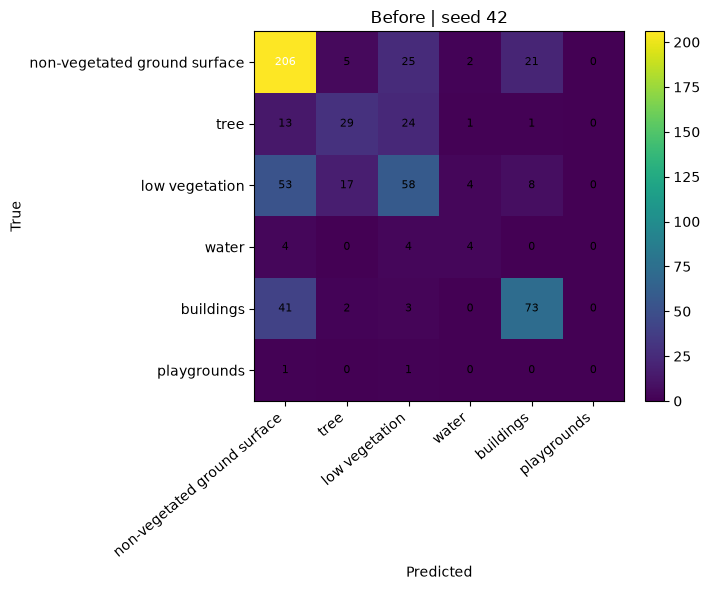


seed=42  after  macro F1=0.5047  macro IoU=0.3725
                       class  support  precision   recall       f1      iou
non-vegetated ground surface      221   0.675889 0.773756 0.721519 0.564356
                        tree       99   0.648352 0.595960 0.621053 0.450382
              low vegetation      101   0.457944 0.485149 0.471154 0.308176
                       water       11   0.571429 0.363636 0.444444 0.285714
                   buildings      167   0.838028 0.712575 0.770227 0.626316
                 playgrounds        1   0.000000 0.000000 0.000000 0.000000


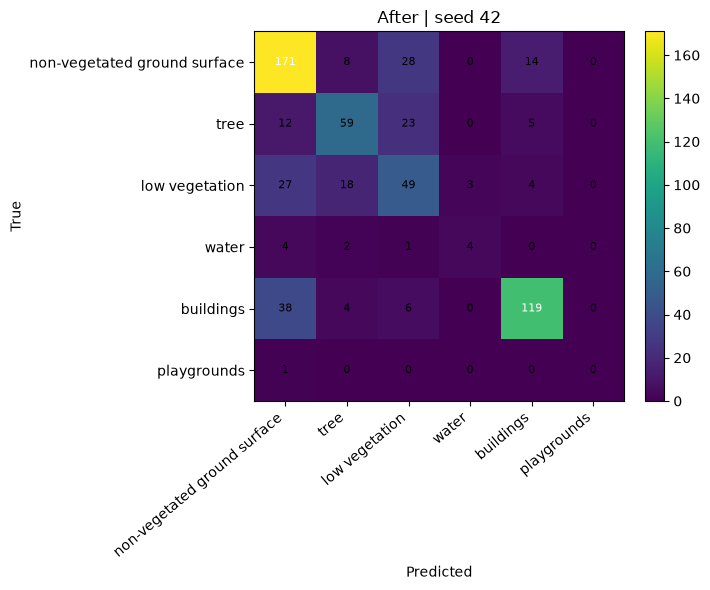

seed=42  joint accuracy=0.4083

seed=123  before  macro F1=0.4329  macro IoU=0.3055
                       class  support  precision   recall       f1      iou
non-vegetated ground surface      259   0.641026 0.772201 0.700525 0.539084
                        tree       68   0.576271 0.500000 0.535433 0.365591
              low vegetation      140   0.496063 0.450000 0.471910 0.308824
                       water       12   0.400000 0.166667 0.235294 0.133333
                   buildings      119   0.736842 0.588235 0.654206 0.486111
                 playgrounds        2   0.000000 0.000000 0.000000 0.000000


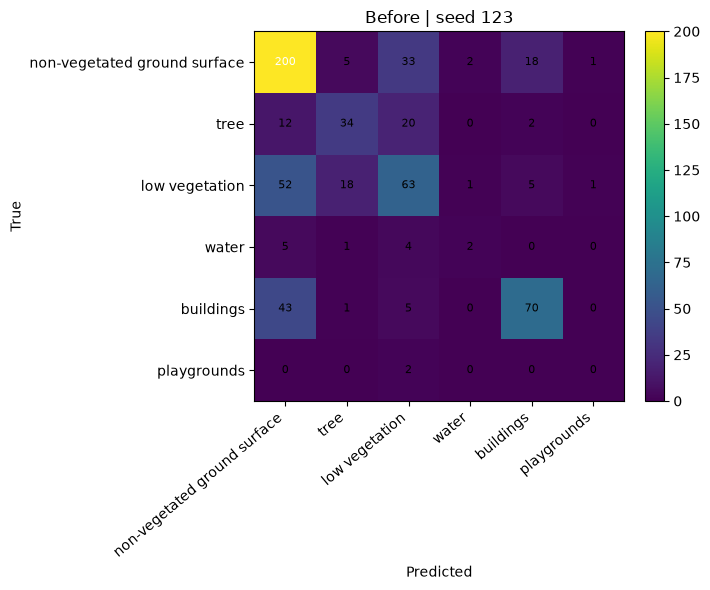


seed=123  after  macro F1=0.4696  macro IoU=0.3453
                       class  support  precision   recall       f1      iou
non-vegetated ground surface      221   0.683594 0.791855 0.733753 0.579470
                        tree       99   0.666667 0.646465 0.656410 0.488550
              low vegetation      101   0.432432 0.475248 0.452830 0.292683
                       water       11   0.400000 0.181818 0.250000 0.142857
                   buildings      167   0.824427 0.646707 0.724832 0.568421
                 playgrounds        1   0.000000 0.000000 0.000000 0.000000


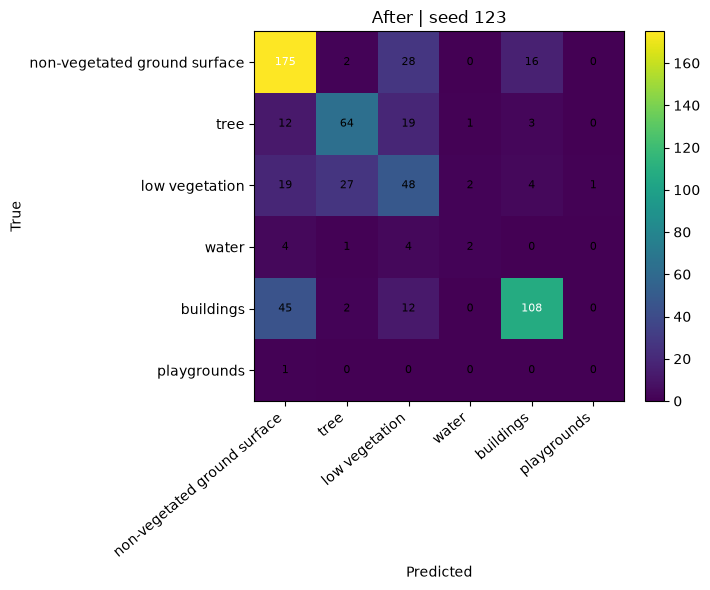

seed=123  joint accuracy=0.4033

seed=777  before  macro F1=0.4215  macro IoU=0.2942
                       class  support  precision   recall       f1      iou
non-vegetated ground surface      259   0.634228 0.729730 0.678636 0.513587
                        tree       68   0.492308 0.470588 0.481203 0.316832
              low vegetation      140   0.440367 0.342857 0.385542 0.238806
                       water       12   0.375000 0.250000 0.300000 0.176471
                   buildings      119   0.686441 0.680672 0.683544 0.519231
                 playgrounds        2   0.000000 0.000000 0.000000 0.000000


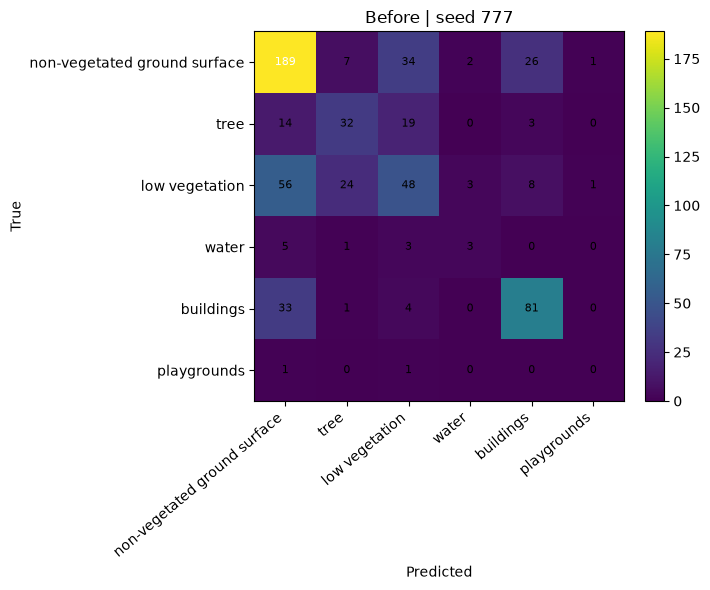


seed=777  after  macro F1=0.4709  macro IoU=0.3476
                       class  support  precision   recall       f1      iou
non-vegetated ground surface      221   0.663968 0.742081 0.700855 0.539474
                        tree       99   0.638095 0.676768 0.656863 0.489051
              low vegetation      101   0.472527 0.425743 0.447917 0.288591
                       water       11   0.400000 0.181818 0.250000 0.142857
                   buildings      167   0.813333 0.730539 0.769716 0.625641
                 playgrounds        1   0.000000 0.000000 0.000000 0.000000


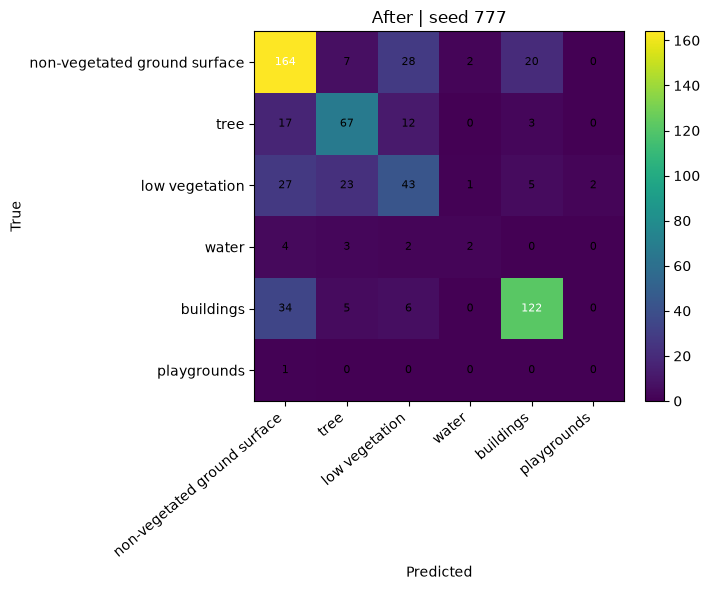

seed=777  joint accuracy=0.4133

Per seed summary:
  seed   date  macro_f1  macro_iou  samples
   42 before  0.442294   0.310891      600
   42  after  0.504733   0.372491      600
  123 before  0.432895   0.305490      600
  123  after  0.469638   0.345330      600
  777 before  0.421488   0.294154      600
  777  after  0.470892   0.347602      600


In [5]:
print('\n===== 1. CONFUSION MATRICES AND CLASS-WISE METRICS =====')
metric_rows=[]
for seed in SEEDS:
    for date in ('before','after'):
        cm,per_class=per_class_stats(val[f'{date}_true'],val[f'{date}_pred_{seed}'])
        per_class.insert(0,'seed',seed)
        per_class.insert(1,'date',date)
        per_class.to_csv(OUTPUT/f'per_class_{date}_seed_{seed}.csv',index=False)
        pd.DataFrame(cm,index=classes,columns=classes).to_csv(
            OUTPUT/f'confusion_{date}_seed_{seed}.csv')
        print(f'\nseed={seed}  {date}  macro F1={per_class.f1.mean():.4f}  '
              f'macro IoU={per_class.iou.mean():.4f}')
        print(per_class[['class','support','precision','recall','f1','iou']].to_string(index=False))
        metric_rows.append({'seed':seed,'date':date,'macro_f1':per_class.f1.mean(),
             'macro_iou':per_class.iou.mean(), 'samples':len(val)})
        make_cm_plot(cm,f'{date.title()} | seed {seed}',OUTPUT/f'confusion_{date}_seed_{seed}.png')
    joint=val[f'both_correct_{seed}'].mean()
    print(f'seed={seed}  joint accuracy={joint:.4f}')
summary_frame=pd.DataFrame(metric_rows)
summary_frame.to_csv(OUTPUT/'macro_metrics_validation.csv',index=False)
print('\nPer seed summary:\n',summary_frame.to_string(index=False))



## 6. Train-ROI audit и baseline

Считает классы, переходы, размеры масок, и наивный majority baseline. Эти показатели сами по себе не равны pixel label purity.

In [6]:
# ----------- 2. ROI label-quality / ambiguity: measurable proxies -------
print('\n===== 2. ROI LABELS, FREQUENCY AND PURITY AUDIT =====')
training_rows=[]
for n,idx in enumerate(train_ids,1):
    s=train_ds[int(idx)]
    info=roi_mask_info(s)
    training_rows.append({'index':int(idx),'sample_id':str(s.get('sample_id',idx)),
         'before_true':int(s['before_label']),'after_true':int(s['after_label']),**info})
    if n%200==0 or n==len(train_ids):
        print('Train audit progress:',n,'/',len(train_ids))
train=pd.DataFrame(training_rows)
train.to_csv(OUTPUT/'train_roi_geometry_and_labels.csv',index=False)
print('Train before class counts:')
print(train.before_true.map(dict(enumerate(classes))).value_counts().to_string())
print('Train after class counts:')
print(train.after_true.map(dict(enumerate(classes))).value_counts().to_string())
print('Train label-pair counts (including within-class transitions):')
print(train.groupby(['before_true','after_true']).size().sort_values(ascending=False).head(15).to_string())
# Simple majority-class baseline on the same sampled validation examples.
major_b=int(train.before_true.mode().iat[0]); major_a=int(train.after_true.mode().iat[0])
base_before=per_class_stats(val.before_true,np.repeat(major_b,len(val)))[1].f1.mean()
base_after=per_class_stats(val.after_true,np.repeat(major_a,len(val)))[1].f1.mean()
base_joint=float(((val.before_true==major_b)&(val.after_true==major_a)).mean())
print(f'Majority baseline from audited train: {classes[major_b]} -> {classes[major_a]}')
print(f'Baseline validation macro F1 (mean two dates)={(base_before+base_after)/2:.4f}; joint={base_joint:.4f}')
print('Train mask fraction / margins:')
print(train[['mask_fraction','minimum_margin_px','minimum_margin_ratio','height','width']].describe().to_string())




===== 2. ROI LABELS, FREQUENCY AND PURITY AUDIT =====
Train audit progress: 200 / 600
Train audit progress: 400 / 600
Train audit progress: 600 / 600
Train before class counts:
before_true
non-vegetated ground surface    290
low vegetation                  141
buildings                       106
tree                             52
playgrounds                       6
water                             5
Train after class counts:
after_true
non-vegetated ground surface    206
buildings                       187
low vegetation                  105
tree                             90
water                            11
playgrounds                       1
Train label-pair counts (including within-class transitions):
before_true  after_true
0            4             147
2            0              95
0            2              75
4            0              74
0            1              61
1            0              32
2            1              22
             4              19
1      

## 7. Pixel-label purity, если подтверждена разметка

Сначала ищет aligned semantic label maps в sample, затем исходные SECOND `label1/label2` с bbox, подтверждаемым прямым совпадением оригинальных RGB. При отсутствии доказанного совмещения не выводит фиктивную чистоту.

In [7]:
# ----------- Optional actual per-pixel SECOND label purity audit ---------
# Need aligned source semantic maps, not just before_label / after_label.
# Source masks can be checked ONLY when they are available aligned with ROI.
LABEL_FIELD_PAIRS = [
 ('before_semantic','after_semantic'), ('semantic_before','semantic_after'),
 ('before_semantic_mask','after_semantic_mask'), ('label_map_before','label_map_after'),
 ('before_label_map','after_label_map'),('label1','label2'),
]
def maybe_label_array(v,shape):
    if isinstance(v,torch.Tensor): v=v.detach().cpu().numpy()
    if isinstance(v,(str,Path)) and Path(v).is_file():
        with Image.open(v) as image: v=np.asarray(image)
    if not isinstance(v,np.ndarray): return None
    if v.ndim==3 and v.shape[0]==1: v=v[0]
    if v.ndim==3 and v.shape[0]==3 and v.shape[1:]==shape: v=np.moveaxis(v,0,-1)
    return v if v.ndim in (2,3) and v.shape[:2]==shape else None

def pixel_purity(arr, mask):
    # SECOND RGB white (255,255,255) means non-change; retain fraction for debugging.
    vals=arr[mask]
    if vals.ndim==1:
        valid = vals != 255 if vals.dtype.kind in 'ui' else np.ones(len(vals),dtype=bool)
    else:
        valid = ~np.all(vals[:,:3]==255,axis=1) if vals.dtype.kind in 'ui' else np.ones(len(vals),dtype=bool)
    vals=vals[valid]
    if len(vals)==0: return np.nan, 0.0
    _,counts=np.unique(vals,axis=0,return_counts=True)
    return float(counts.max()/len(vals)),float(len(vals)/max(mask.sum(),1))

# Optional: locate original SECOND label1/label2 using explicit ROI provenance.
# We never assume an undocumented coordinate convention: RGB pixels must match.
manifest_doc = json.loads(manifest.read_text(encoding='utf-8'))
metadata_by_id={}
def visit_records(obj):
    if isinstance(obj,dict):
        if 'sample_id' in obj and isinstance(obj['sample_id'],str):
            metadata_by_id.setdefault(obj['sample_id'],obj)
        for value in obj.values(): visit_records(value)
    elif isinstance(obj,list):
        for value in obj: visit_records(value)
visit_records(manifest_doc)

try:
    raw_layout = discover_second(ROOT/'data/SECOND')
except (OSError, ValueError, FileNotFoundError) as e:
    raw_layout={}
    print('Raw SECOND label-map lookup unavailable:',str(e))
raw_scenes=[]
for split,items in raw_layout.items():
    for item in items:
        if isinstance(item,dict): raw_scenes.append(item)

def path_field(mapping,keys):
    for key in keys:
        val=mapping.get(key)
        if isinstance(val,(str,Path)) and Path(val).is_file():
            return Path(val)
    return None

def find_source(record,sample_id):
    hints=[record[k] for k in ('source_sample_id','source_id','scene_id','source_scene',
           'original_sample_id','source_image_id') if isinstance(record.get(k),str)]
    for source in raw_scenes:
        scene_id=str(source.get('sample_id',''))
        if scene_id and (scene_id in hints or scene_id.split('/')[-1] in hints):
            return source
    # Only allow unique, delimiter-separated matches, then verify actual RGB alignment.
    matches=[]
    import re
    for source in raw_scenes:
        sid=str(source.get('sample_id','')).split('/')[-1]
        if len(sid)>3 and re.search(r'(?<![A-Za-z0-9])'+re.escape(sid)+r'(?![A-Za-z0-9])',sample_id):
            matches.append(source)
    return matches[0] if len(matches)==1 else None

def boxes_from_record(record,height,width):
    coords=[]
    for parent in (record,record.get('roi',{}),record.get('source',{})):
        if not isinstance(parent,dict):continue
        for key in ('bbox_xyxy','crop_xyxy','crop_box','roi_box','bbox','bounds'):
            vals=parent.get(key)
            if isinstance(vals,(list,tuple)) and len(vals)==4:
                try: a,b,c,d=map(int,vals)
                except (TypeError,ValueError): continue
                coords.extend([(a,b,c,d),(b,a,d,c)])
        if all(key in parent for key in ('x0','y0','x1','y1')):
            coords.append(tuple(int(parent[k]) for k in ('x0','y0','x1','y1')))
        if all(key in parent for key in ('xmin','ymin','xmax','ymax')):
            coords.append(tuple(int(parent[k]) for k in ('xmin','ymin','xmax','ymax')))
        if all(key in parent for key in ('left','top','right','bottom')):
            coords.append(tuple(int(parent[k]) for k in ('left','top','right','bottom')))
    return list(dict.fromkeys(box for box in coords
        if box[2]-box[0]==width and box[3]-box[1]==height and box[0]>=0 and box[1]>=0))

@lru_cache(maxsize=6)
def read_original_image(filename):
    with Image.open(filename) as im:
        return np.array(im.convert('RGB'))

@lru_cache(maxsize=6)
def read_original_label(filename):
    with Image.open(filename) as im:
        return np.array(im)

def aligned_label_maps(sample):
    sample_id=str(sample.get('sample_id',''))
    record=metadata_by_id.get(sample_id,{})
    if not isinstance(record,dict):return None
    source=find_source(record,sample_id)
    if not source:return None
    label_before=path_field(source,('label1','before_label','before_label_path','label_before','label_before_path'))
    label_after=path_field(source,('label2','after_label','after_label_path','label_after','label_after_path'))
    image_before=path_field(source,('im1','before','before_image','before_path','image1'))
    image_after=path_field(source,('im2','after','after_image','after_path','image2'))
    if not all((label_before,label_after,image_before,image_after)):
        return None
    before=(sample['before'].detach().cpu().permute(1,2,0).numpy()*255).round().clip(0,255).astype(np.uint8)
    after=(sample['after'].detach().cpu().permute(1,2,0).numpy()*255).round().clip(0,255).astype(np.uint8)
    height,width=before.shape[:2]
    src_before=read_original_image(str(image_before))
    src_after=read_original_image(str(image_after))
    for x0,y0,x1,y1 in boxes_from_record(record,height,width):
        if y1>src_before.shape[0] or x1>src_before.shape[1]: continue
        region_before=src_before[y0:y1,x0:x1]
        region_after=src_after[y0:y1,x0:x1]
        # Reject coordinate guesses, altered/scaled crops or augmented scenes.
        if np.mean(np.abs(region_before.astype('int16')-before.astype('int16'))) > 1.0:continue
        if np.mean(np.abs(region_after.astype('int16')-after.astype('int16'))) > 1.0:continue
        lb=read_original_label(str(label_before))
        la=read_original_label(str(label_after))
        if lb.shape[:2]!=src_before.shape[:2] or la.shape[:2]!=src_after.shape[:2]:
            continue
        return lb[y0:y1,x0:x1],la[y0:y1,x0:x1], 'verified source label1/label2 RGB-crop alignment'
    return None

purity_rows=[]
for idx in val_ids[:MAX_RAW_PURITY_ROIS]:
    s=val_ds[int(idx)]
    mask=(np.squeeze(s['mask'].detach().cpu().numpy())>0.5)
    aligned = None
    for before_key,after_key in LABEL_FIELD_PAIRS:
        a=maybe_label_array(s.get(before_key),mask.shape)
        b=maybe_label_array(s.get(after_key),mask.shape)
        if a is not None and b is not None:
            aligned=(a,b,f'{before_key}/{after_key}')
            break
    if aligned is None:
        aligned=aligned_label_maps(s)
    if aligned is not None:
        a,b,provenance=aligned
        pb,vb=pixel_purity(a,mask)
        pa,va=pixel_purity(b,mask)
        purity_rows.append({'index':int(idx),'sample_id':str(s.get('sample_id',idx)),
             'dominant_label_fraction_before':pb,'dominant_label_fraction_after':pa,
             'labeled_fraction_before':vb,'labeled_fraction_after':va,
             'source_fields':provenance})
if purity_rows:
    purity=pd.DataFrame(purity_rows)
    purity.to_csv(OUTPUT/'pixel_label_purity_validation.csv',index=False)
    print('Pixel-label purity computed for:',len(purity),'/',min(len(val_ids),MAX_RAW_PURITY_ROIS),'ROIs')
    print(purity.describe().to_string())
    print('Below 80% dominant semantic label, before/after:',
          (purity.dominant_label_fraction_before<0.8).sum(),
          (purity.dominant_label_fraction_after<0.8).sum())
    joined=purity.merge(val[['index',f'both_correct_{SEEDS[0]}']],on='index',how='inner')
    joined['mixed_any_date']=(joined.dominant_label_fraction_before<0.8)|(
        joined.dominant_label_fraction_after<0.8)
    print('Joint accuracy (seed',SEEDS[0],') by mixed vs dominant semantics:')
    print(joined.groupby('mixed_any_date')[f'both_correct_{SEEDS[0]}'].agg(['size','mean']).to_string())
    print('Dominant pixel fraction measures mixing only, not agreement with saved ROI class ID.')
else:
    print('TRUE PIXEL LABEL PURITY: NOT AVAILABLE from SemanticROIDataset samples.')
    print('Scalar before_label / after_label and binary ROI mask cannot establish whether')
    print('a crop contains competing semantic classes. To measure that, the source')
    print('SECOND label1/label2 rasters and ROI source-image coordinates are needed.')
    manifest_doc=json.loads(manifest.read_text(encoding='utf-8'))
    print('Manifest top-level keys:',list(manifest_doc)[:35] if isinstance(manifest_doc,dict) else type(manifest_doc))
    example=val_ds[int(val_ids[0])]
    print('Dataset sample fields:',{k:(tuple(v.shape) if hasattr(v,'shape') else type(v).__name__)
                              for k,v in example.items()})
    print('Please provide src/satchange/semantic/second.py and data.py to add')
    print('source-aligned pixel purity without inventing coordinates or class maps.')



TRUE PIXEL LABEL PURITY: NOT AVAILABLE from SemanticROIDataset samples.
Scalar before_label / after_label and binary ROI mask cannot establish whether
a crop contains competing semantic classes. To measure that, the source
SECOND label1/label2 rasters and ROI source-image coordinates are needed.
Manifest top-level keys: ['schema_version', 'protocol', 'provenance', 'records', 'coverage', 'coverage_definition', 'mask_hashes', 'second']
Dataset sample fields: {'before': (3, 128, 128), 'after': (3, 128, 128), 'mask': (1, 128, 128), 'sample_id': 'str', 'before_label': 'int', 'after_label': 'int'}
Please provide src/satchange/semantic/second.py and data.py to add
source-aligned pixel purity without inventing coordinates or class maps.


## 8. Сколько контекста оставлено?

Сравнивает точность пар классов с расстоянием от маски до краёв crop; визуализирует трудные ROI. Корреляция ошибок не доказывает, что расширение crop повысит F1.


===== 3. CONTEXT AROUND CHANGE / ERROR CORRELATION =====
Validation margin / mask coverage:
           height       width  mask_fraction  minimum_margin_px  minimum_margin_ratio
count  600.000000  600.000000     600.000000         600.000000            600.000000
mean   138.428333  138.215000       0.077606          27.976667              0.217753
std     39.492416   37.868617       0.108427          21.884569              0.171527
min    128.000000  128.000000       0.000061           0.000000              0.000000
25%    128.000000  128.000000       0.007004           4.000000              0.031250
50%    128.000000  128.000000       0.034454          25.000000              0.195312
75%    128.000000  128.000000       0.095428          48.000000              0.375000
max    485.000000  512.000000       0.757060          63.000000              0.492188
Fraction of masks touching ROI edge: 0.2267
 seed   margin_category  rois  mean_joint_accuracy  mean_macro_f1_two_dates  mean_mask_fr

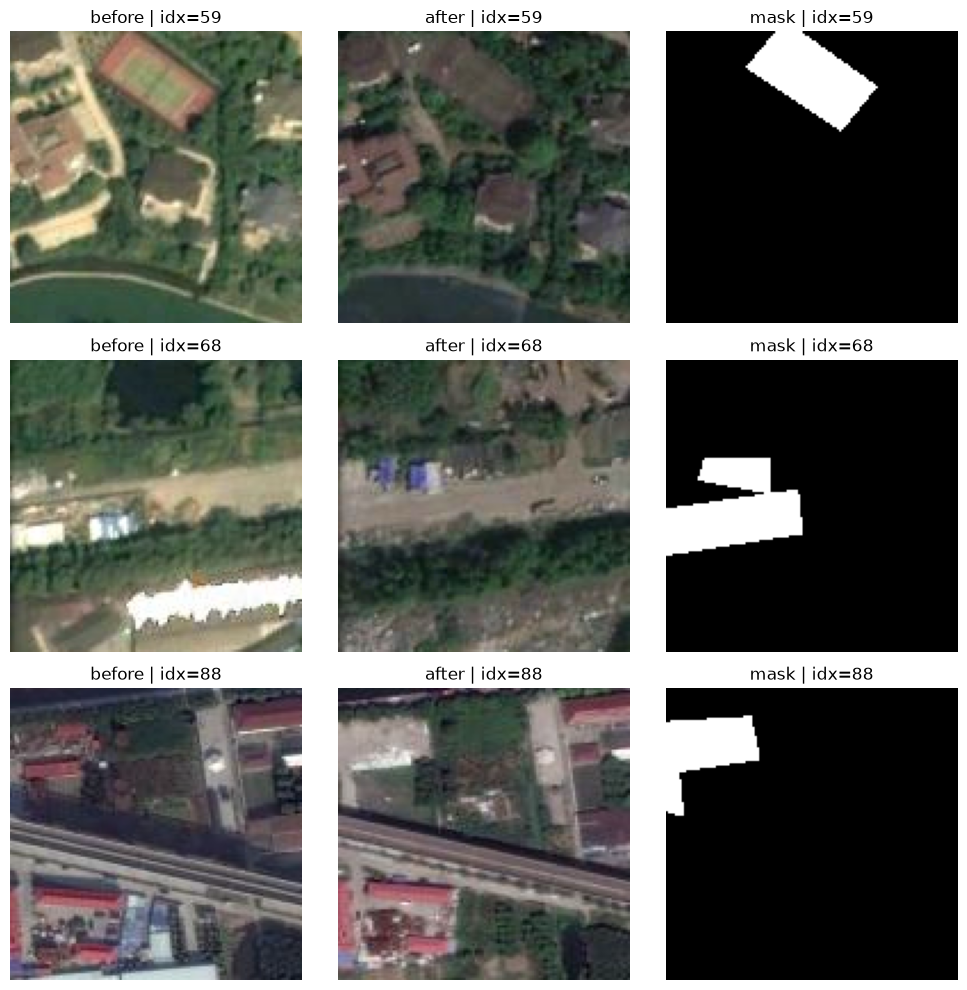


DONE. Report directory: artifacts/debug/tiny_second_roi_diagnostics/second_oracle_bounded21_e15_25_40_65_bf16_w4_v1
Context-vs-errors is observational, not an experiment increasing crop padding.
If pixel purity is NOT AVAILABLE, do not infer it from mask_fraction.


In [8]:
# ------------ 3. Context margins and relationship with mistakes --------
print('\n===== 3. CONTEXT AROUND CHANGE / ERROR CORRELATION =====')
print('Validation margin / mask coverage:')
print(val[['height','width','mask_fraction','minimum_margin_px','minimum_margin_ratio']].describe().to_string())
print('Fraction of masks touching ROI edge:',round(val.touches_border.mean(),4))
val['context_bin']=pd.cut(val.minimum_margin_ratio,
    bins=[-0.001,0,0.02,0.05,0.10,np.inf],
    labels=['0% (touches edge)','0–2%','2–5%','5–10%','>10%'])
context_rows=[]
for seed in SEEDS:
    for b,grp in val.groupby('context_bin',observed=True):
        fb=per_class_stats(grp.before_true,grp[f'before_pred_{seed}'])[1].f1.mean()
        fa=per_class_stats(grp.after_true,grp[f'after_pred_{seed}'])[1].f1.mean()
        context_rows.append({'seed':seed,'margin_category':str(b),'rois':len(grp),
               'mean_joint_accuracy':float(grp[f'both_correct_{seed}'].mean()),
               'mean_macro_f1_two_dates':float((fb+fa)/2),
               'mean_mask_fraction':float(grp.mask_fraction.mean())})
context=pd.DataFrame(context_rows)
context.to_csv(OUTPUT/'context_vs_joint_accuracy.csv',index=False)
print(context.to_string(index=False))
print('\nWorst tight-margin validation examples:')
columns=['sample_id','height','width','minimum_margin_px','minimum_margin_ratio','mask_fraction',
         f'both_correct_{SEEDS[0]}']
print(val.sort_values(['minimum_margin_ratio','mask_fraction'])[columns].head(12).to_string(index=False))

# Display a few tight ROI to determine whether wider context might be useful.
fig,axes=plt.subplots(3,3,figsize=(10,10))
for row,record in enumerate(pd.concat([val[val[f'both_correct_{SEEDS[0]}']==0].nsmallest(3,'minimum_margin_ratio'), val.nsmallest(3,'minimum_margin_ratio')]).drop_duplicates(subset=['index']).head(3).itertuples()):
    s=val_ds[int(record.index)]
    for col,key in enumerate(('before','after','mask')):
        a=s[key].detach().cpu().numpy()
        if key!='mask': a=np.transpose(a,(1,2,0))
        else: a=a[0]
        axes[row,col].imshow(a,cmap='gray' if key=='mask' else None)
        axes[row,col].set_title(f'{key} | idx={record.index}')
        axes[row,col].axis('off')
fig.tight_layout()
fig.savefig(OUTPUT/'tight_context_examples.png',dpi=140)
plt.show()
plt.close(fig)

print('\nDONE. Report directory:',OUTPUT)
print('Context-vs-errors is observational, not an experiment increasing crop padding.')
print('If pixel purity is NOT AVAILABLE, do not infer it from mask_fraction.')
